# Batch imbalance analysis

In [1]:
import os
import sys
import scanpy as sc
import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import seaborn as sns
import math
import colorcet as cc
from bs4 import BeautifulSoup
import json
import re
import glob

import matplotlib.font_manager as font_manager

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

import sys
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/')
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scripts/project_utils/')
os.environ["R_HOME"] = "/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/R"

mm_s = pd.read_csv('../scib/scib/resources/s_genes_tirosh.txt', header=None, index_col=0).index.to_numpy()
mm_g2m = pd.read_csv('../scib/scib/resources/g2m_genes_tirosh.txt', header=None, index_col=0).index.to_numpy()

hg_s = pd.read_csv('../scib/scib/resources/s_genes_tirosh_hm.txt', header=None, index_col=0).index.to_numpy()
hg_g2m = pd.read_csv('../scib/scib/resources/g2m_genes_tirosh_hm.txt', header=None, index_col=0).index.to_numpy()

from analysis_helpers import *
import scib
from scib.metrics import *

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
def make_fig(df, y, ylabel, invert=False, show_legend=False, legend_ncols=3):
    fig, ax = plt.subplots(1, 1, figsize=(1.3, 1.7))

    sns.lineplot(
        data=df, 
        x='imbalance', 
        y=y, 
        hue='Integration', 
        marker='o', 
        markeredgewidth=0,
        markersize=2,
        linewidth=.5, 
        palette=INTEGRATION_COLOR_DICT, 
        ax=ax
    )
    if show_legend:
        sns.move_legend(
            ax, 
            "upper left", 
            bbox_to_anchor=(1, 1),
            ncols=legend_ncols,
            frameon=False,
            title="Integration",
            fontsize=5,
            title_fontsize=5,
            handlelength=1.0,
            columnspacing=0.8,
        )
    else:
        legend = ax.get_legend()
        if legend is not None:
            legend.remove()
    ax.patch.set_alpha(1.0)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    xticks = sorted(df['imbalance'].unique())
    ax.set_xticks(xticks)
    ax.set_xticklabels(['2.30', '2.26', '2.20', '2.10', '1.99', '1.79', '1.55', '0.94', '0.54'], rotation=45)
    ax.set_xlabel('')
    ax.set_ylabel(ylabel, fontsize=5)
    if invert:
        ax.invert_yaxis()
    for spine in ax.spines.values():
        spine.set_linewidth(.45)
    ax.grid(True, linestyle='--', alpha=0.7, linewidth=.25)
    for artist in ax.get_children():
        if hasattr(artist, 'get_rasterized') and artist.get_rasterized():
            print(artist, "is rasterized")
    fig.patch.set_alpha(0.0)
    ax.patch.set_alpha(0.0)
    return fig, ax

In [3]:
def compute_w_across_integrations(df, metric_cols=None, id_cols=('Dataset', 'Integration', 'LabelKey', 'imbalance')):
    if metric_cols is None:
        metric_cols = [c for c in df.columns if c not in id_cols]

    def compute_T(ranks_series):
        tie_counts = ranks_series.value_counts()
        tied = tie_counts[tie_counts > 1]
        return (tied**3 - tied).sum()

    results = []
    for metric in metric_cols:
        work = df[['Integration', 'imbalance', metric]].copy()

        work['Rank'] = work.groupby('imbalance')[metric].rank(ascending=False, method='average')

        pivot = work.pivot_table(index='Integration', columns='imbalance', values='Rank', aggfunc='first')

        n = pivot.shape[0]
        m = pivot.shape[1]

        R_i = pivot.sum(axis=1)
        sum_T = pivot.apply(compute_T, axis=0).sum()

        numerator   = 12 * (R_i**2).sum() - 3 * (m**2) * n * (n + 1)**2
        denominator = (m**2) * n * (n**2 - 1) - m * sum_T
        W = numerator / denominator if denominator != 0 else 0.0

        results.append({'Metric': metric, 'Kendall_W': W})

    return pd.DataFrame(results)

Data file: `../results/source_data/batch_imbalance.csv`

In [4]:
df = pd.read_csv('../results/dataset_ablation/batch_imbalance_v2/metrics/all-metrics.csv')

In [5]:
df['imbalance'] = df['Dataset'].str.split('_').str[-1].astype(int) + 1

In [6]:
df = df.pivot(index=['Dataset', 'Integration', 'imbalance'], columns='Metric', values='Value').reset_index()

In [7]:
df['BIO'] = (df['BAMI'] + df['CASW'] + df['SCGRAPHM']) / 3
df['BATCH'] = (df['CPCR'] + df['BRAS'] + df['KBET']) / 3
df['OVERALL'] = df['BIO'] * .6 + df['BATCH'] * .4

In [8]:
df['Integration'] = df['Integration'].str[:-2]

In [9]:
df['Integration'] = df["Integration"].replace(NAME_MAP)

In [10]:
df = df[~df.Integration.isin(['INSCT', 'SAUCIE'])]

In [11]:
# Remove the extra experiment 5
df = df[df['imbalance'] != 5]
df['imbalance'] = df['imbalance'].replace({6: 5, 7:6, 8:7, 9:8, 10:9})

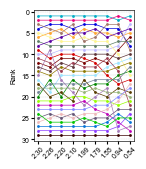

In [12]:
df['Rank'] = df.groupby(['imbalance'])['OVERALL'].rank(ascending=False, method='min')

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'Rank', 'Rank', invert=True, show_legend=False)
#     plt.savefig('../publication_figures/batch_imbalance_rank.svg', bbox_inches='tight')
    plt.show()

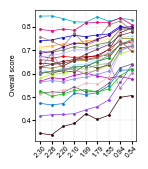

In [13]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'OVERALL', 'Overall score', invert=False)
#     plt.savefig('../publication_figures/batch_imbalance_overall.svg', bbox_inches='tight')
    plt.show()

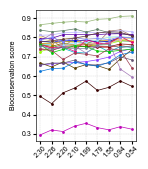

In [14]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'BIO', 'Bioconservation score', invert=False)
#     plt.savefig('../publication_figures/batch_imbalance_bio.svg', bbox_inches='tight')
    plt.show()

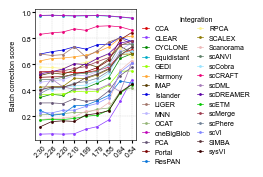

In [15]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'BATCH', 'Batch correction score', invert=False, show_legend=True, legend_ncols=2)
#     plt.savefig('../publication_figures/batch_imbalance_batch.svg', bbox_inches='tight')
    plt.show()

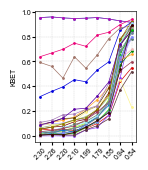

In [16]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'KBET', 'KBET', invert=False)
    plt.show()

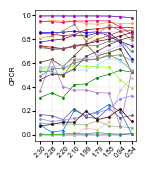

In [17]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'CPCR', 'CPCR', invert=False)
    plt.show()

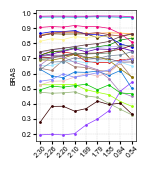

In [18]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'BRAS', 'BRAS', invert=False)
    plt.show()

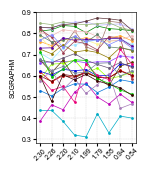

In [19]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'SCGRAPHM', 'SCGRAPHM', invert=False)
    plt.show()

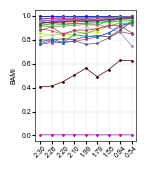

In [20]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'BAMI', 'BAMI', invert=False)
    plt.show()

In [22]:
for i in range(1, 10):
    for j in range(i+1, 10):
        x = df[df['imbalance'] == i].sort_values('Integration')['Rank']
        y = df[df['imbalance'] == j].sort_values('Integration')['Rank']
        
        print(i, j)
        print(scipy.stats.kendalltau(x, y).statistic)

1 2
0.8965517241379308
1 3
0.921182266009852
1 4
0.9064039408866994
1 5
0.8866995073891624
1 6
0.8669950738916254
1 7
0.8719211822660098
1 8
0.7536945812807881
1 9
0.6059113300492609
2 3
0.9064039408866994
2 4
0.9113300492610836
2 5
0.8522167487684726
2 6
0.8719211822660098
2 7
0.8669950738916254
2 8
0.7487684729064038
2 9
0.6009852216748768
3 4
0.9359605911330047
3 5
0.9261083743842363
3 6
0.9359605911330047
3 7
0.9113300492610836
3 8
0.8029556650246304
3 9
0.6748768472906402
4 5
0.9113300492610836
4 6
0.9408866995073891
4 7
0.9162561576354677
4 8
0.8275862068965516
4 9
0.6699507389162561
5 6
0.9507389162561575
5 7
0.8965517241379308
5 8
0.817733990147783
5 9
0.6896551724137929
6 7
0.9359605911330047
6 8
0.8374384236453202
6 9
0.7192118226600984
7 8
0.8620689655172412
7 9
0.6945812807881773
8 9
0.8029556650246304


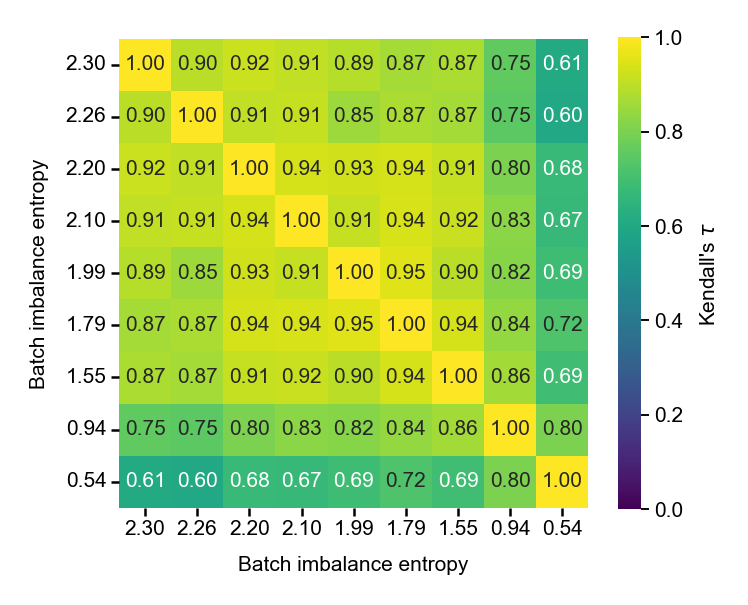

In [23]:
M = np.array([
    [1.000, 0.897, 0.921, 0.906, 0.887, 0.867, 0.872, 0.754, 0.606],
    [0.897, 1.000, 0.906, 0.911, 0.852, 0.872, 0.867, 0.749, 0.601],
    [0.921, 0.906, 1.000, 0.936, 0.926, 0.936, 0.911, 0.803, 0.675],
    [0.906, 0.911, 0.936, 1.000, 0.911, 0.941, 0.916, 0.828, 0.670],
    [0.887, 0.852, 0.926, 0.911, 1.000, 0.951, 0.897, 0.818, 0.690],
    [0.867, 0.872, 0.936, 0.941, 0.951, 1.000, 0.936, 0.837, 0.719],
    [0.872, 0.867, 0.911, 0.916, 0.897, 0.936, 1.000, 0.862, 0.695],
    [0.754, 0.749, 0.803, 0.828, 0.818, 0.837, 0.862, 1.000, 0.803],
    [0.606, 0.601, 0.675, 0.670, 0.690, 0.719, 0.695, 0.803, 1.000],
])

with plt.rc_context({'figure.dpi': 300}):
    labels = ['2.30', '2.26', '2.20', '2.10', '1.99', '1.79', '1.55', '0.94', '0.54']

    plt.figure(figsize=(2.8, 2.8))
    ax = sns.heatmap(M, annot=True, fmt=".2f", cmap="viridis",
                xticklabels=labels, yticklabels=labels,
                annot_kws={'fontsize': 5},
                vmin=0, vmax=1, square=True, cbar_kws={"label": "Kendall's $\\tau$", 'shrink': 0.7})
    
    plt.setp(ax.get_xticklabels(), fontsize=5)
    plt.setp(ax.get_yticklabels(), fontsize=5)
    cbar = ax.collections[0].colorbar
    cbar.set_label("Kendall's $\\tau$", fontsize=5)
    cbar.ax.tick_params(
        which='major', width=.45,
        length=2, labelsize=5, pad=1
    )
    plt.xticks(rotation=0)
    plt.yticks(rotation=0) 
    ax.tick_params(
        axis='both', which='major', width=.6,
        length=2, labelsize=5, pad=1
    )
    ax.set_xlabel('Batch imbalance entropy', fontsize=5)
    ax.set_ylabel('Batch imbalance entropy', fontsize=5)
    plt.tight_layout()
#     plt.savefig('../publication_figures/batch_imbalance_kendall_tau_heatmap.svg', dpi=300, bbox_inches='tight')
    plt.show()